# Aprendizado de máquina sem bibliotecas de alto nível

Este notebook implementa três modelos vistos nos slides: regressão linear para prever o consumo de uma máquina, regressão logística para classificação binária de e-mails e regressão softmax para classificação multiclasse.

Usaremos apenas NumPy para os cálculos e Matplotlib para os gráficos. As funções de previsão, perda, gradiente e treinamento serão escritas passo a passo. Não usaremos Scikit-learn.

Os dados são sintéticos. Eles simulam os exemplos da apresentação e permitem observar o que o algoritmo faz; não representam medições reais.

## Ferramentas básicas

Começamos importando NumPy e Matplotlib. A função abaixo separa dados de treinamento e teste sem uma biblioteca de aprendizado de máquina. O conjunto de teste ficará fora do ajuste dos parâmetros.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

def split_train_test(X, y, test_fraction=0.25, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(y))
    n_test = int(round(test_fraction * len(y)))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# 1. Regressão linear: prever consumo de energia

Cada exemplo descreve o tempo de funcionamento e a carga da máquina. O alvo é o consumo de energia. Vamos gerar dados segundo uma relação aproximadamente linear, com ruído:

$$y = 0{,}6 + 1{,}4x_1 + 2{,}2x_2 + \varepsilon.$$

O treinamento não recebe os coeficientes verdadeiros. Ele começa com valores iniciais e os ajusta para reduzir o erro quadrático médio.

In [2]:
rng = np.random.default_rng(1734)
n = 160

horas = rng.uniform(0.5, 5.0, size=n)
carga = rng.uniform(0.0, 1.0, size=n)
ruido = rng.normal(0.0, 0.35, size=n)

consumo = 0.6 + 1.4 * horas + 2.2 * carga + ruido
X = np.column_stack([horas, carga])

X_train, X_test, y_train, y_test = split_train_test(
    X, consumo, test_fraction=0.25, seed=10
)

print("Exemplos de treinamento:", len(y_train))
print("Exemplos de teste:", len(y_test))
print("Primeiras cinco linhas [horas, carga]:")
print(X_train[:5])
print("Consumos correspondentes:")
print(y_train[:5])

Exemplos de treinamento: 120
Exemplos de teste: 40
Primeiras cinco linhas [horas, carga]:
[[0.827 0.041]
 [0.905 0.863]
 [1.105 0.682]
 [1.912 0.882]
 [2.613 0.27 ]]
Consumos correspondentes:
[2.131 3.035 3.49  5.489 4.584]


## Escrevendo o modelo e o custo

Incluímos uma coluna de uns para representar o intercepto. Assim, todos os parâmetros ficam no vetor $\boldsymbol\theta=(b,w_1,w_2)$:

$$\hat{\mathbf y}=X\boldsymbol\theta.$$

Para o MSE, o gradiente em relação aos parâmetros é:

$$\nabla J(\boldsymbol\theta)=\frac{2}{n}X^\top(X\boldsymbol\theta-\mathbf y).$$

A expressão usa todos os exemplos de treinamento em cada atualização. Esse procedimento é o gradiente descendente em lote.

In [3]:
def add_intercept(X):
    return np.column_stack([np.ones(len(X)), X])

def predict_linear(X_with_intercept, theta):
    return X_with_intercept @ theta

def mean_squared_error(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def mse_gradient(X_with_intercept, y_true, theta):
    errors = predict_linear(X_with_intercept, theta) - y_true
    return (2 / len(y_true)) * (X_with_intercept.T @ errors)

X_train_b = add_intercept(X_train)
X_test_b = add_intercept(X_test)

# Inicialização: intercepto e pesos começam em zero.
theta = np.zeros(X_train_b.shape[1])
learning_rate = 0.02
n_steps = 2500
mse_history = []

for step in range(n_steps):
    gradient = mse_gradient(X_train_b, y_train, theta)
    theta = theta - learning_rate * gradient
    mse_history.append(
        mean_squared_error(y_train, predict_linear(X_train_b, theta))
    )

print("Parâmetros aprendidos [intercepto, peso_horas, peso_carga]:")
print(theta)
print("Coeficientes usados para gerar os dados: [0.6, 1.4, 2.2]")

Parâmetros aprendidos [intercepto, peso_horas, peso_carga]:
[0.584 1.427 2.125]
Coeficientes usados para gerar os dados: [0.6, 1.4, 2.2]


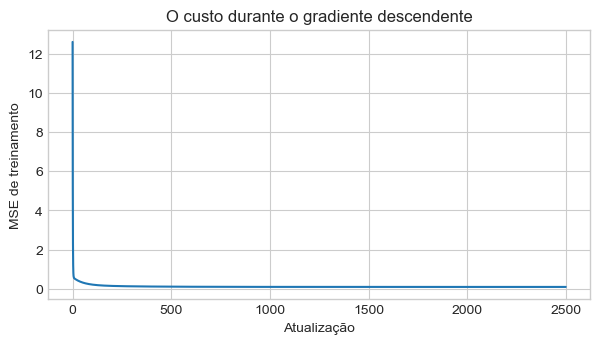

In [4]:
plt.figure(figsize=(7, 3.5))
plt.plot(mse_history)
plt.xlabel("Atualização")
plt.ylabel("MSE de treinamento")
plt.title("O custo durante o gradiente descendente")
plt.show()

O custo de treinamento deve cair à medida que o algoritmo encontra parâmetros melhores para esses dados. Agora avaliamos o modelo no conjunto de teste, que não participou dos cálculos do gradiente.

MSE de treinamento: 0.096
MSE de teste:       0.107


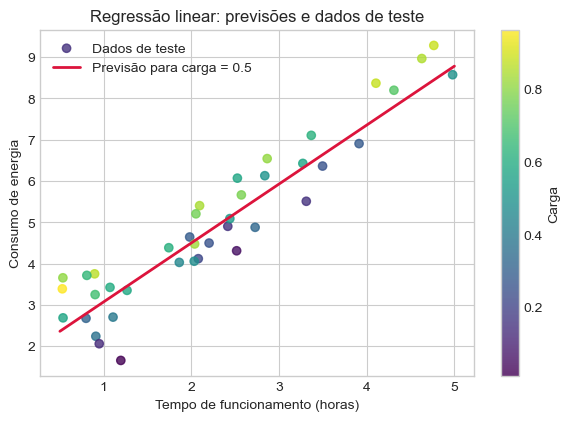

In [5]:
train_predictions = predict_linear(X_train_b, theta)
test_predictions = predict_linear(X_test_b, theta)

print(f"MSE de treinamento: {mean_squared_error(y_train, train_predictions):.3f}")
print(f"MSE de teste:       {mean_squared_error(y_test, test_predictions):.3f}")

# Visualizamos consumo versus horas. A linha mostra a previsão para uma carga fixa.
load_reference = 0.5
hours_grid = np.linspace(0.5, 5.0, 100)
grid = np.column_stack([
    np.ones(len(hours_grid)),
    hours_grid,
    np.full(len(hours_grid), load_reference),
])
line_predictions = grid @ theta

plt.figure(figsize=(7, 4.5))
scatter = plt.scatter(
    X_test[:, 0], y_test, c=X_test[:, 1], cmap="viridis",
    alpha=0.8, label="Dados de teste"
)
plt.plot(
    hours_grid, line_predictions, color="crimson", linewidth=2,
    label=f"Previsão para carga = {load_reference}"
)
plt.xlabel("Tempo de funcionamento (horas)")
plt.ylabel("Consumo de energia")
plt.title("Regressão linear: previsões e dados de teste")
plt.colorbar(scatter, label="Carga")
plt.legend()
plt.show()

### O que o algoritmo fez?

Em cada passo, o modelo calculou previsões, comparou-as aos consumos observados, calculou o gradiente do MSE e atualizou os três parâmetros. A fórmula do gradiente codifica o mesmo raciocínio do exemplo dos slides, agora aplicado a duas características.

# 2. Classificação binária: e-mail legítimo ou spam

Representaremos cada e-mail por dois valores entre zero e um: um indicador de linguagem suspeita e um indicador de presença de links. Os rótulos são gerados aleatoriamente, com maior probabilidade de spam quando esses indicadores aumentam.

A regressão logística calcula um escore linear $z$, aplica a sigmoide para obter uma probabilidade e usa entropia cruzada binária como função de perda.

In [6]:
def sigmoid(z):
    # O limite evita overflow numérico em exp.
    z = np.clip(z, -35, 35)
    return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(28)
n_emails = 800

linguagem_suspeita = rng.uniform(0, 1, size=n_emails)
indicador_links = rng.uniform(0, 1, size=n_emails)
X_email = np.column_stack([linguagem_suspeita, indicador_links])

# Processo sintético que gera os rótulos.
X_email_b = add_intercept(X_email)
theta_email_source = np.array([-3.8, 4.2, 3.4])
spam_probability_source = sigmoid(X_email_b @ theta_email_source)
y_spam = rng.binomial(1, spam_probability_source)

Xb_train_raw, Xb_test_raw, yb_train, yb_test = split_train_test(
    X_email, y_spam, test_fraction=0.25, seed=11
)
Xb_train = add_intercept(Xb_train_raw)
Xb_test = add_intercept(Xb_test_raw)

print("Proporção de spam no treinamento:", round(yb_train.mean(), 3))
print("Exemplo de entrada [linguagem suspeita, indicador de links]:")
print(Xb_train_raw[:5])
print("Rótulos (0 = legítimo, 1 = spam):")
print(yb_train[:5])

Proporção de spam no treinamento: 0.51
Exemplo de entrada [linguagem suspeita, indicador de links]:
[[0.058 0.665]
 [0.549 0.901]
 [0.126 0.872]
 [0.781 0.329]
 [0.103 0.913]]
Rótulos (0 = legítimo, 1 = spam):
[0 0 0 0 1]


## Sigmoide, entropia cruzada e gradiente

Para um exemplo, a previsão é $p=\sigma(\mathbf{x}^\top\boldsymbol\theta)$. A perda é pequena quando o modelo atribui probabilidade alta à classe correta e cresce quando atribui probabilidade baixa.

Para a média da entropia cruzada binária, o gradiente tem uma forma simples:

$$\nabla J(\boldsymbol\theta)=\frac{1}{n}X^\top(\mathbf p-\mathbf y).$$

Implementaremos essa expressão diretamente.

In [7]:
def binary_cross_entropy(y_true, probabilities):
    eps = 1e-12
    p = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

def train_logistic_regression(X_with_intercept, y, learning_rate=0.2, n_steps=2500):
    theta = np.zeros(X_with_intercept.shape[1])
    history = []

    for step in range(n_steps):
        probabilities = sigmoid(X_with_intercept @ theta)
        gradient = (X_with_intercept.T @ (probabilities - y)) / len(y)
        theta = theta - learning_rate * gradient
        history.append(
            binary_cross_entropy(y, sigmoid(X_with_intercept @ theta))
        )

    return theta, history

theta_logistic, logistic_history = train_logistic_regression(
    Xb_train, yb_train, learning_rate=0.2, n_steps=2500
)

print("Parâmetros aprendidos [intercepto, linguagem, links]:")
print(theta_logistic)

Parâmetros aprendidos [intercepto, linguagem, links]:
[-3.398  3.627  3.116]


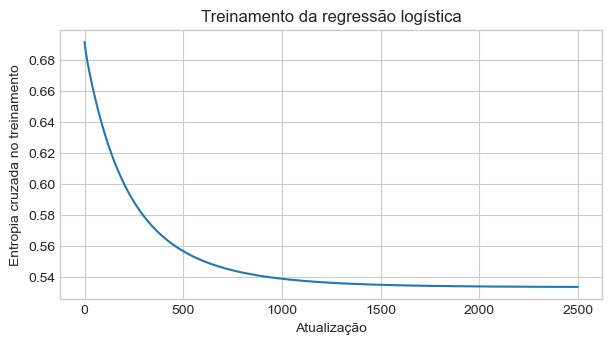

In [8]:
plt.figure(figsize=(7, 3.5))
plt.plot(logistic_history)
plt.xlabel("Atualização")
plt.ylabel("Entropia cruzada no treinamento")
plt.title("Treinamento da regressão logística")
plt.show()

## Probabilidades, decisão e avaliação

A sigmoide produz probabilidades. Para transformar cada probabilidade em uma classe, adotamos aqui o limiar 0,5. A matriz de confusão abaixo é construída com NumPy: linhas são classes verdadeiras e colunas são classes previstas.

In [9]:
probabilities_test = sigmoid(Xb_test @ theta_logistic)
predictions_test = (probabilities_test >= 0.5).astype(int)

accuracy = np.mean(predictions_test == yb_test)

confusion_binary = np.zeros((2, 2), dtype=int)
for true_label, predicted_label in zip(yb_test, predictions_test):
    confusion_binary[true_label, predicted_label] += 1

print(f"Acurácia no teste: {accuracy:.3f}")
print("Matriz de confusão (linhas = real; colunas = previsto):")
print(confusion_binary)

Acurácia no teste: 0.745
Matriz de confusão (linhas = real; colunas = previsto):
[[70 25]
 [26 79]]


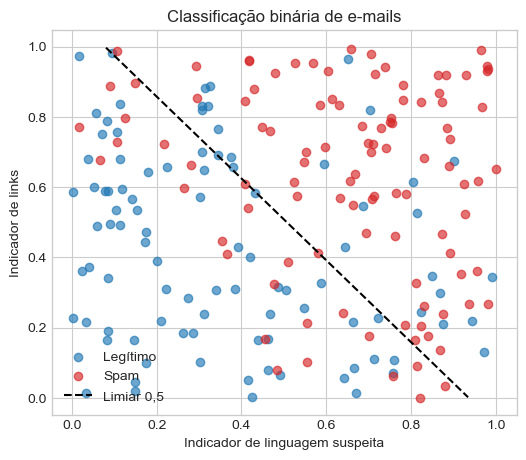

In [10]:
plt.figure(figsize=(6, 5))
for label, name, color in [
    (0, "Legítimo", "tab:blue"),
    (1, "Spam", "tab:red"),
]:
    mask = yb_test == label
    plt.scatter(
        Xb_test_raw[mask, 0], Xb_test_raw[mask, 1],
        label=name, color=color, alpha=0.65
    )

# Fronteira em que a probabilidade prevista é 0.5, isto é, z = 0.
x_line = np.linspace(0, 1, 200)
if abs(theta_logistic[2]) > 1e-10:
    y_line = -(theta_logistic[0] + theta_logistic[1] * x_line) / theta_logistic[2]
    in_plot = (y_line >= 0) & (y_line <= 1)
    plt.plot(x_line[in_plot], y_line[in_plot], "k--", label="Limiar 0,5")

plt.xlabel("Indicador de linguagem suspeita")
plt.ylabel("Indicador de links")
plt.title("Classificação binária de e-mails")
plt.legend()
plt.show()

# 3. Classificação multiclasse: pessoal, trabalho ou spam

Agora cada exemplo pertence a uma entre três classes. Usaremos dois indicadores sintéticos: linguagem pessoal e presença de links promocionais. As classes são geradas em regiões diferentes do plano para que possamos visualizar as fronteiras aprendidas.

O modelo produz um logit por classe. A softmax converte os logits em probabilidades cuja soma é um. A perda é a entropia cruzada multiclasse.

In [11]:
rng = np.random.default_rng(73)
class_names = np.array(["Pessoal", "Trabalho", "Spam"])
centers = np.array([
    [0.78, 0.18],  # pessoal: linguagem pessoal alta, poucos links promocionais
    [0.18, 0.20],  # trabalho: linguagem pessoal baixa, poucos links promocionais
    [0.46, 0.80],  # spam: muitos links promocionais
])

n_per_class = 220
X_multi = np.vstack([
    rng.normal(loc=center, scale=[0.11, 0.11], size=(n_per_class, 2))
    for center in centers
])
X_multi = np.clip(X_multi, 0, 1)
y_multi = np.repeat(np.arange(len(class_names)), n_per_class)

Xm_train_raw, Xm_test_raw, ym_train, ym_test = split_train_test(
    X_multi, y_multi, test_fraction=0.25, seed=12
)
Xm_train = add_intercept(Xm_train_raw)
Xm_test = add_intercept(Xm_test_raw)

n_classes = len(class_names)
Y_train = np.eye(n_classes)[ym_train]

print("Número de classes:", n_classes)
print("Formato da matriz de rótulos one-hot:", Y_train.shape)
print("Exemplo de rótulo one-hot:", Y_train[0])

Número de classes: 3
Formato da matriz de rótulos one-hot: (495, 3)
Exemplo de rótulo one-hot: [1. 0. 0.]


## Implementando softmax e entropia cruzada

Para cada linha da matriz de entradas, a operação softmax é aplicada aos logits. Subtrair o maior logit antes de calcular exponenciais evita problemas numéricos e não altera as probabilidades resultantes.

In [12]:
def softmax(logits):
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)

def multiclass_cross_entropy(Y_one_hot, probabilities):
    eps = 1e-12
    p = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(np.sum(Y_one_hot * np.log(p), axis=1))

def train_softmax_regression(X_with_intercept, Y_one_hot,
                             learning_rate=0.5, n_steps=2000):
    # Uma coluna de pesos por classe.
    W = np.zeros((X_with_intercept.shape[1], Y_one_hot.shape[1]))
    history = []

    for step in range(n_steps):
        probabilities = softmax(X_with_intercept @ W)
        gradient = (X_with_intercept.T @ (probabilities - Y_one_hot)) / len(Y_one_hot)
        W = W - learning_rate * gradient
        history.append(
            multiclass_cross_entropy(Y_one_hot, softmax(X_with_intercept @ W))
        )

    return W, history

W_multi, multiclass_history = train_softmax_regression(
    Xm_train, Y_train, learning_rate=0.5, n_steps=2000
)
print("Formato da matriz de parâmetros:", W_multi.shape)

Formato da matriz de parâmetros: (3, 3)


In [13]:
probabilities_multi = softmax(Xm_test @ W_multi)
predictions_multi = np.argmax(probabilities_multi, axis=1)
accuracy_multi = np.mean(predictions_multi == ym_test)

confusion_multi = np.zeros((n_classes, n_classes), dtype=int)
for true_label, predicted_label in zip(ym_test, predictions_multi):
    confusion_multi[true_label, predicted_label] += 1

print(f"Acurácia no teste: {accuracy_multi:.3f}")
print("Matriz de confusão (linhas = real; colunas = previsto):")
print(confusion_multi)
print("Ordem das classes:", list(class_names))

Acurácia no teste: 1.000
Matriz de confusão (linhas = real; colunas = previsto):
[[47  0  0]
 [ 0 58  0]
 [ 0  0 60]]
Ordem das classes: [np.str_('Pessoal'), np.str_('Trabalho'), np.str_('Spam')]


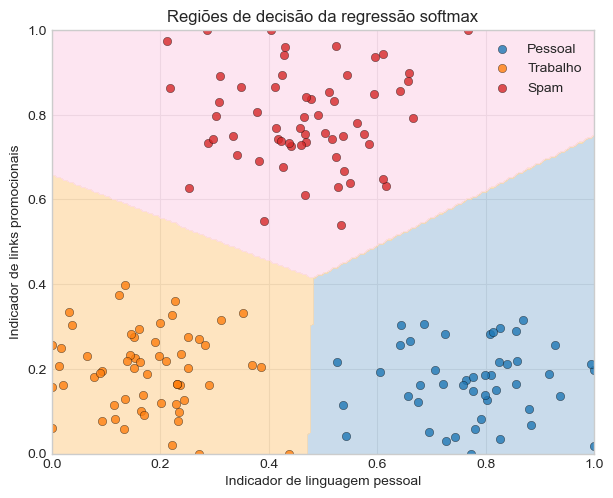

In [14]:
plt.figure(figsize=(7, 5.5))

# Região prevista pelo classificador em uma malha de pontos.
x1_grid = np.linspace(0, 1, 180)
x2_grid = np.linspace(0, 1, 180)
xx1, xx2 = np.meshgrid(x1_grid, x2_grid)
grid_raw = np.column_stack([xx1.ravel(), xx2.ravel()])
grid_with_intercept = add_intercept(grid_raw)
region = np.argmax(softmax(grid_with_intercept @ W_multi), axis=1)
region = region.reshape(xx1.shape)

plt.contourf(
    xx1, xx2, region, levels=[-0.5, 0.5, 1.5, 2.5],
    cmap="Pastel1", alpha=0.7
)

colors = ["tab:blue", "tab:orange", "tab:red"]
for class_id, name, color in zip(range(n_classes), class_names, colors):
    mask = ym_test == class_id
    plt.scatter(
        Xm_test_raw[mask, 0], Xm_test_raw[mask, 1],
        label=name, color=color, edgecolor="black", linewidth=0.3, alpha=0.8
    )

plt.xlabel("Indicador de linguagem pessoal")
plt.ylabel("Indicador de links promocionais")
plt.title("Regiões de decisão da regressão softmax")
plt.legend()
plt.show()

## Comparando as três tarefas

| Tarefa | Saída do modelo | Perda usada aqui |
|---|---|---|
| Regressão linear | Valor numérico | Erro quadrático médio |
| Classificação binária | Probabilidade entre 0 e 1 | Entropia cruzada binária |
| Classificação multiclasse | Distribuição sobre as classes | Entropia cruzada multiclasse |

Nos três casos, ajustamos parâmetros a partir de dados. Mudam a forma da saída e a função de perda.

### Para explorar

1. Na regressão, altere a taxa de aprendizado. O custo diminui mais rápido, oscila ou diverge?
2. Na classificação binária, compare os resultados com limiares 0,3, 0,5 e 0,7. A acurácia muda? O que acontece com falsos positivos e falsos negativos?
3. Na classificação multiclasse, reduza o número de exemplos ou aumente a dispersão dos grupos. Como mudam as fronteiras e os erros?